# Harbor House Café: ¿el sentimiento escrito respalda el promedio de 4.5 estrellas?

**Cliente:** WeLoveReviews · **Negocio:** Harbor House Café  
**Dataset:** 500 reseñas de servicio (`review_id`, `rating`, `review_text`)  
**Pregunta de negocio:** el negocio muestra una media de **4.5 / 5**; ¿el tono de lo que escriben los clientes respalda esa cifra?

## 1. Objetivos

Al terminar este notebook queremos responder tres preguntas y dejar un artefacto reproducible:

1. **¿Cómo se distribuye el sentimiento escrito?** Clasificar las 500 reseñas en positivo, neutral y negativo.
2. **¿Coincide con el 4.5?** Comparar la distribución del texto con la distribución implícita en las estrellas y con la media de 4.5.
3. **¿Dónde falla el modelo?** Identificar falsos negativos, revisar una muestra a mano y explicar los patrones.

El entregable de producción es `data/processed/reviews_with_sentiment.csv`, generado por `src/app.py` con el mismo modelo fijado.

## 2. Setup y carga

Fijamos rutas, el modelo y el mapeo antes de tocar los datos. La revisión del modelo es un **commit inmutable**, no `main` ni `latest`.

In [1]:
# Importaciones de análisis, gráficos y rutas.
from pathlib import Path
import os
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Silenciamos warnings y barras de progreso para mantener limpia la salida.
warnings.filterwarnings("ignore")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 250)
pd.set_option("display.width", 180)


# El notebook puede ejecutarse desde la raíz o desde src/: buscamos la raíz.
def find_project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "reviews.csv").exists():
            return candidate
    raise FileNotFoundError("No se encontró data/raw/reviews.csv")


# Configuración fija del experimento: modelo, revisión, batch y mapeo.
ROOT = find_project_root()
RAW_PATH = ROOT / "data" / "raw" / "reviews.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "reviews_with_sentiment.csv"

MODEL_ID = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"
BATCH_SIZE = 32
MAX_LENGTH = 512

STAR_TO_BAND = {
    1: "negative",
    2: "negative",
    3: "neutral",
    4: "positive",
    5: "positive",
}
SENTIMENT_ORDER = ["positive", "neutral", "negative"]
# Columnas exactas del CSV de producción.
OUTPUT_COLUMNS = [
    "review_id",
    "rating",
    "review_text",
    "predicted_stars",
    "predicted_label",
    "predicted_sentiment",
    "confidence",
    "expected_stars",
    "prob_1_star",
    "prob_2_star",
    "prob_3_star",
    "prob_4_star",
    "prob_5_star",
    "star_implied_sentiment",
    "agrees_with_rating",
    "is_false_negative",
    "model_id",
    "model_revision",
]

print(f"Raíz del proyecto: {ROOT}")
print(f"Modelo fijado: {MODEL_ID}")
print(f"Revisión fijada: {MODEL_REVISION}")

Raíz del proyecto: /Users/jesus/projects/geeks-academy/machine-learning-python-template
Modelo fijado: nlptown/bert-base-multilingual-uncased-sentiment
Revisión fijada: 8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d


## 3. Perfilado del dataset

Antes de modelar, comprobamos forma, tipos, valores faltantes, duplicados y longitud de los textos.

In [2]:
# Carga del CSV original.
df = pd.read_csv(RAW_PATH)
# Normalizamos tipos y espacios; no alteramos el contenido de las reseñas.
df["rating"] = pd.to_numeric(df["rating"], errors="raise").astype(int)
df["review_text"] = (
    df["review_text"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
# Métricas de longitud que usaremos en el EDA.
df["char_len"] = df["review_text"].str.len()
df["word_count"] = df["review_text"].str.split().str.len()

print(f"Filas: {len(df):,} | Columnas originales: review_id, rating, review_text")
print(f"Tipos: rating={df['rating'].dtype}, review_text={df['review_text'].dtype}")
display(df[["review_id", "rating", "review_text"]].head(3))

Filas: 500 | Columnas originales: review_id, rating, review_text
Tipos: rating=int64, review_text=string


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.


In [3]:
# Perfilado rápido: nulos, duplicados, distribución y riqueza léxica.
print("Valores faltantes en columnas clave:")
display(df[["review_id", "rating", "review_text"]].isna().sum().to_frame("nulos"))

print(f"review_id duplicados: {df['review_id'].duplicated().sum()}")
print(f"textos duplicados: {df['review_text'].duplicated().sum()}")
print(f"textos vacíos: {(df['review_text'] == '').sum()}")

# Distribución de ratings y su peso relativo.
rating_summary = (
    df["rating"].value_counts().sort_index().rename_axis("rating").to_frame("n")
)
rating_summary["share_pct"] = (rating_summary["n"] / len(df) * 100).round(1)
display(rating_summary)

# Estadísticas de longitud de texto.
text_stats = df[["char_len", "word_count"]].describe().T
display(text_stats.round(1))

# Riqueza léxica: cuántas palabras distintas hay en todo el corpus.
tokens = re.findall(r"[A-Za-z']+", " ".join(df["review_text"]))
print(f"Palabras únicas (case-insensitive): {len(set(t.lower() for t in tokens))}")
print(f"Reseñas que mencionan 'Harbor House Café': {df['review_text'].str.contains('Harbor House Café', regex=False).sum()}")

Valores faltantes en columnas clave:


,nulos
review_id,0
rating,0
review_text,0


review_id duplicados: 0
textos duplicados: 7
textos vacíos: 0


,n,share_pct
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


,count,mean,std,min,25%,50%,75%,max
char_len,500.0,170.17,27.058778,86.0,155.0,173.0,189.0,230.0
word_count,500.0,29.104,4.824078,14.0,26.0,29.0,32.0,42.0


Palabras únicas (case-insensitive): 235
Reseñas que mencionan 'Harbor House Café': 433


Miramos una reseña de cada nivel de rating y la relación entre longitud y puntuación.

In [4]:
# Una reseña de cada rating para inspeccionar el tono de cada nivel.
display(
    df.groupby("rating", group_keys=False)
    .head(1)[["review_id", "rating", "review_text"]]
    .sort_values("rating")
)

# Longitud media y mediana por rating.
print("Longitud por rating:")
display(
    df.groupby("rating")[["char_len", "word_count"]]
    .agg(["mean", "median"])
    .round(1)
)

,review_id,rating,review_text
77,78,1,Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning.
31,32,2,Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning.
8,9,3,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop."
13,14,4,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.


Longitud por rating:


char_len        word_count       
           mean median       mean median
rating                                  
1         175.3  179.5       30.2   29.5
2         151.3  156.0       26.4   26.0
3         152.7  158.0       26.8   27.0
4         182.3  186.0       30.5   31.5
5         170.4  172.0       29.2   29.0

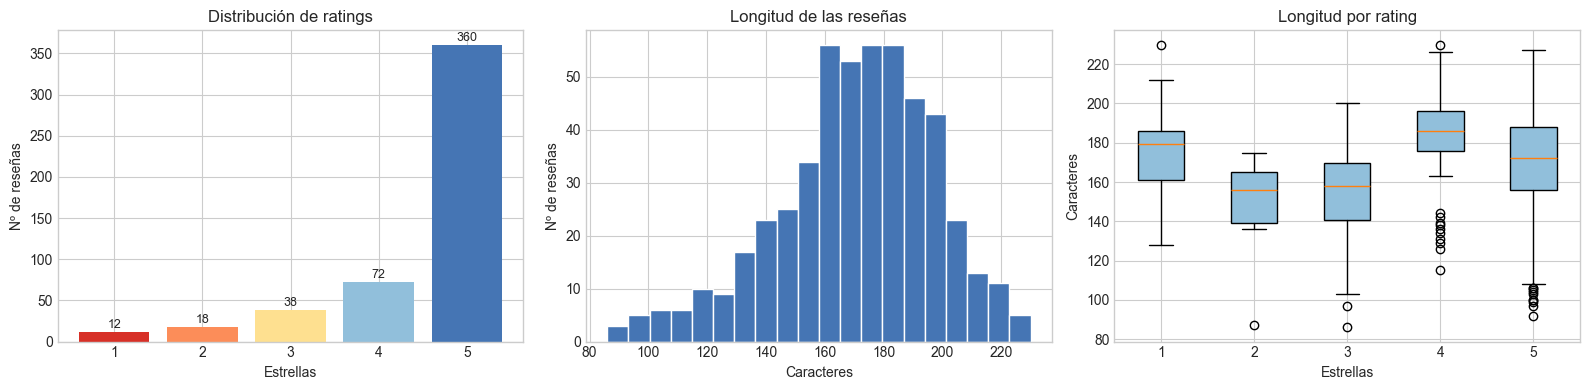

In [5]:
%matplotlib inline

# Tres vistas del EDA: distribución de ratings y longitud del texto.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

colors = ["#d73027", "#fc8d59", "#fee090", "#91bfdb", "#4575b4"]
# Barras con el número de reseñas por rating.
axes[0].bar(rating_summary.index.astype(str), rating_summary["n"], color=colors)
axes[0].set_title("Distribución de ratings")
axes[0].set_xlabel("Estrellas")
axes[0].set_ylabel("Nº de reseñas")
for x, y in zip(rating_summary.index.astype(str), rating_summary["n"]):
    axes[0].text(x, y + 5, str(y), ha="center", fontsize=9)

# Histograma de longitud global.
axes[1].hist(df["char_len"], bins=20, color="#4575b4", edgecolor="white")
axes[1].set_title("Longitud de las reseñas")
axes[1].set_xlabel("Caracteres")
axes[1].set_ylabel("Nº de reseñas")

# Boxplot para comparar longitudes entre ratings.
axes[2].boxplot(
    [df.loc[df["rating"] == stars, "char_len"] for stars in range(1, 6)],
    tick_labels=[str(s) for s in range(1, 6)],
    patch_artist=True,
    boxprops=dict(facecolor="#91bfdb"),
)
axes[2].set_title("Longitud por rating")
axes[2].set_xlabel("Estrellas")
axes[2].set_ylabel("Caracteres")

plt.tight_layout()
plt.show()

### Insights del EDA

- **La media 4.5 es real, pero está muy concentrada:** 360 reseñas son de 5★ (72.0%), 72 de 4★ (14.4%), 38 de 3★ (7.6%) y solo 30 de 1–2★ (6.0%). En total, **432 (86.4%)** son de 4–5★.
- **El texto es corto y muy plantillado:** entre 86 y 230 caracteres, mediana 173, ~29 palabras y solo **235 palabras únicas**. Hay **7 textos duplicados**. Esto importa: una sola frase puede dominar la predicción.
- **El dataset ya está limpio:** no hay nulos, textos vacíos, URLs, HTML, emails ni emojis. El único carácter no ASCII relevante es la tilde de “Café”.
- **No hay que eliminar duplicados:** son `review_id` distintos; quitarlos reduciría el denominador de 500 y perdería reseñas válidas.
- **La conclusión no puede salir solo del promedio:** 4.5 es compatible con un 6% de reseñas negativas. Necesitamos mirar el texto y, sobre todo, los casos mixtos.

## 4. Limpieza

La limpieza será mínima y explícita. No lowercaso, no quito puntuación ni stopwords: el transformer necesita el texto natural. Solo normalizo espacios y tipos.

In [6]:
# Helper para contar coincidencias de patrones de limpieza.
def count_matches(pattern: str, series: pd.Series) -> int:
    return int(series.map(lambda text: bool(re.search(pattern, text))).sum())


# Buscamos problemas típicos antes de decidir si hace falta limpiar.
cleaning_checks = pd.Series(
    {
        "Nulos en columnas clave": int(df[["review_id", "rating", "review_text"]].isna().sum().sum()),
        "Textos vacíos": int((df["review_text"] == "").sum()),
        "URLs": count_matches(r"https?://|www\.", df["review_text"]),
        "HTML": count_matches(r"<[^>]+>", df["review_text"]),
        "Emails": count_matches(r"\S+@\S+", df["review_text"]),
        "Emojis": count_matches(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", df["review_text"]),
        "Espacios dobles": int(df["review_text"].str.contains("  ", regex=False).sum()),
        "Saltos de línea": count_matches(r"[\r\n]", df["review_text"]),
    },
    name="casos",
)
display(cleaning_checks.to_frame())

# Limpieza real: normalizar espacios y tipos, sin eliminar filas.
df_clean = df.drop(columns=["char_len", "word_count"]).copy()
df_clean["review_text"] = (
    df_clean["review_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Validaciones para no continuar con datos incompletos.
assert len(df_clean) == 500
assert df_clean["review_text"].notna().all()
assert (df_clean["review_text"] != "").all()
print(f"Filas tras limpieza: {len(df_clean)} (no se eliminó ninguna)")

,casos
Nulos en columnas clave,0
Textos vacíos,0
URLs,0
HTML,0
Emails,0
Emojis,0
Espacios dobles,0
Saltos de línea,0


Filas tras limpieza: 500 (no se eliminó ninguna)


## 5. Plan de acción y justificación del modelo

Los insights anteriores llevan a un plan simple:

1. **No entrenar un modelo nuevo.** El encargo pide integrar un modelo existente, no construir uno.
2. **Usar un clasificador ordinal de 1–5 estrellas**, porque así podemos comparar directamente con el rating humano y derivar bandas de sentimiento.
3. **Cargarlo una sola vez** y pasarlo por las 500 reseñas en batch.
4. **Guardar estrellas predichas, banda, confianza y probabilidades** para poder auditar los desacuerdos.
5. **Revisar a mano los falsos negativos**, porque un modelo de producto puede no entender el lenguaje de servicio.

### Decisión: `nlptown/bert-base-multilingual-uncased-sentiment`

- Ya está fine-tuned para predecir **1–5 estrellas** en reseñas, justo la granularidad que necesitamos.
- Es multilingüe y funciona bien en inglés, el idioma del dataset.
- Está disponible vía `transformers` con `pipeline()` / `from_pretrained()`.
- Fijamos la revisión `8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d` para que el resultado sea reproducible.

### Mapeo de bandas

| Estrellas | Banda |
|---:|---|
| 1–2 | negative |
| 3 | neutral |
| 4–5 | positive |

### Limitación que vamos a poner a prueba

El modelo fue entrenado con reseñas de **productos** (mayoritariamente inglés y francés), no con reseñas de **servicios** como las de un café. Frases de servicio (“went out of their way to accommodate my allergy”) pueden quedar fuera de su distribución. La sección de falsos negativos comprobará si eso ocurre y con qué patrones.

## 6. Carga única del modelo

Instanciamos tokenizer, modelo y pipeline **una sola vez**. Las celdas siguientes reutilizan `sentiment`; no se recarga por reseña.

In [7]:
# Importamos transformers aquí, después de fijar variables de entorno.
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()

# Carga única del tokenizer, modelo y pipeline.
t0 = time.perf_counter()
# La revisión fijada garantiza que el modelo no cambie entre ejecuciones.
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION
)
# El pipeline se reutiliza para las 500 reseñas y para el test de frases.
sentiment = pipeline(
    "sentiment-analysis",
    model=model,
    tokenizer=tokenizer,
    device=-1,
    truncation=True,
    max_length=MAX_LENGTH,
)
load_seconds = time.perf_counter() - t0

print(f"Modelo cargado en {load_seconds:.1f} s")
print(f"Etiquetas: {model.config.id2label}")
print("El pipeline queda reutilizable para las 500 reseñas y para el diagnóstico de frases.")

Modelo cargado en 0.2 s
Etiquetas: {0: '1 star', 1: '2 stars', 2: '3 stars', 3: '4 stars', 4: '5 stars'}
El pipeline queda reutilizable para las 500 reseñas y para el diagnóstico de frases.


## 7. Inferencia sobre las 500 reseñas

Una sola llamada al pipeline con la lista completa de textos y `batch_size=32`. Después parseamos la salida a estrellas, banda, confianza y probabilidades.

In [8]:
# Una sola llamada en batch para las 500 reseñas.
t0 = time.perf_counter()
raw_predictions = sentiment(
    df_clean["review_text"].tolist(),
    batch_size=BATCH_SIZE,
    truncation=True,
    max_length=MAX_LENGTH,
    top_k=5,
)
inference_seconds = time.perf_counter() - t0

# Parseamos la salida: top_k=5 devuelve las cinco etiquetas por reseña.
rows = []
for predictions in raw_predictions:
    probabilities = {
        int(item["label"].split()[0]): float(item["score"])
        for item in predictions
    }
    best = max(predictions, key=lambda item: item["score"])
    predicted_stars = int(best["label"].split()[0])

    row = {
        "predicted_stars": predicted_stars,
        "predicted_label": best["label"],
        "confidence": float(best["score"]),
        "expected_stars": sum(
            stars * probabilities[stars] for stars in range(1, 6)
        ),
    }
    for stars in range(1, 6):
        row[f"prob_{stars}_star"] = probabilities[stars]
    rows.append(row)

# Unimos las predicciones al dataframe limpio.
scored = pd.concat([df_clean.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
# Derivamos bandas, acuerdo y la definición estricta de falso negativo.
scored["predicted_sentiment"] = scored["predicted_stars"].map(STAR_TO_BAND)
scored["star_implied_sentiment"] = scored["rating"].map(STAR_TO_BAND)
scored["agrees_with_rating"] = (
    scored["predicted_sentiment"] == scored["star_implied_sentiment"]
)
scored["is_false_negative"] = (scored["rating"] >= 4) & (
    scored["predicted_stars"] <= 2
)
scored["model_id"] = MODEL_ID
scored["model_revision"] = MODEL_REVISION

# Controles de integridad: 500 filas y predicciones válidas.
assert len(scored) == 500
assert scored["predicted_stars"].notna().all()
assert scored["predicted_stars"].between(1, 5).all()

print(f"Inferencia completada en {inference_seconds:.1f} s")
print(f"Reseñas procesadas: {len(scored)}/500")
display(
    scored[
        [
            "review_id",
            "rating",
            "review_text",
            "predicted_stars",
            "predicted_sentiment",
            "confidence",
        ]
    ].head(5)
)

Inferencia completada en 9.6 s
Reseñas procesadas: 500/500


,review_id,rating,review_text,predicted_stars,predicted_sentiment,confidence
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,5,positive,0.716958
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.,5,positive,0.982220
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.,5,positive,0.662323
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,5,positive,0.989547
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,5,positive,0.982912


## 8. Distribución y comparación con el promedio de 4.5

Comparamos dos cosas distintas: la **banda implícita por las estrellas humanas** y la **banda que asigna el modelo al texto**. La primera es el “debería ser” según el rating; la segunda es lo que realmente dice la reseña.

In [9]:
# Distribuciones que vamos a comparar: humana (implícita) y modelo.
human_avg = scored["rating"].mean()
pred_avg = scored["predicted_stars"].mean()
expected_avg = scored["expected_stars"].mean()

star_counts = (
    scored["star_implied_sentiment"]
    .value_counts()
    .reindex(SENTIMENT_ORDER, fill_value=0)
)
model_counts = (
    scored["predicted_sentiment"]
    .value_counts()
    .reindex(SENTIMENT_ORDER, fill_value=0)
)

# Tabla comparativa con brecha en puntos porcentuales.
comparison = pd.DataFrame(
    {
        "Implícito por estrellas (n)": star_counts.astype(int),
        "Implícito por estrellas (%)": (star_counts / len(scored) * 100).round(1),
        "Modelo (n)": model_counts.astype(int),
        "Modelo (%)": (model_counts / len(scored) * 100).round(1),
    }
)
comparison["Brecha (pp)"] = (
    comparison["Modelo (%)"] - comparison["Implícito por estrellas (%)"]
).round(1)
comparison.index.name = "Sentimiento"
display(comparison)

# Métricas agregadas de calibración.
metrics = pd.DataFrame(
    {
        "Métrica": [
            "Media de estrellas humanas",
            "Media de estrellas predichas (argmax)",
            "Media de estrellas esperada (Σ p·s)",
            "Acuerdo con la banda implícita",
            "Falsos negativos estrictos",
        ],
        "Valor": [
            f"{human_avg:.2f}",
            f"{pred_avg:.2f}",
            f"{expected_avg:.2f}",
            f"{scored['agrees_with_rating'].mean():.1%}",
            f"{int(scored['is_false_negative'].sum())} ({scored['is_false_negative'].mean():.1%})",
        ],
    }
)
display(metrics)

# Matriz de confusión rating humano vs banda predicha.
confusion = (
    pd.crosstab(scored["rating"], scored["predicted_sentiment"])
    .reindex(columns=SENTIMENT_ORDER, fill_value=0)
)
confusion.index.name = "Rating humano"
confusion.columns.name = "Sentimiento predicho"
display(confusion)

,Implícito por estrellas (n),Implícito por estrellas (%),Modelo (n),Modelo (%),Brecha (pp)
Sentimiento,,,,,
positive,432,86.4,412,82.4,-4.0
neutral,38,7.6,41,8.2,0.6
negative,30,6.0,47,9.4,3.4


,Métrica,Valor
0,Media de estrellas humanas,4.50
1,Media de estrellas predichas (argmax),4.40
2,Media de estrellas esperada (Σ p·s),4.19
3,Acuerdo con la banda implícita,95.0%
4,Falsos negativos estrictos,16 (3.2%)


Sentimiento predicho,positive,neutral,negative
Rating humano,,,
1,0,0,12
2,0,2,16
3,0,35,3
4,68,3,1
5,344,1,15


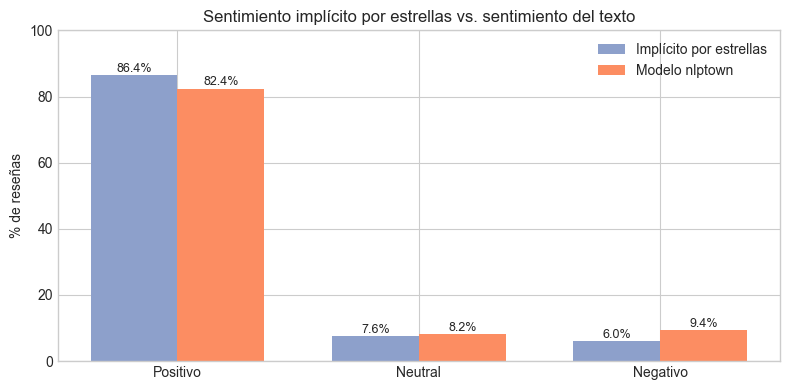

In [10]:
# Gráfico de barras agrupadas para comparar ambas distribuciones.
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(SENTIMENT_ORDER))
width = 0.36

ax.bar(
    x - width / 2,
    comparison["Implícito por estrellas (%)"],
    width,
    label="Implícito por estrellas",
    color="#8da0cb",
)
ax.bar(
    x + width / 2,
    comparison["Modelo (%)"],
    width,
    label="Modelo nlptown",
    color="#fc8d62",
)
ax.set_xticks(x, ["Positivo", "Neutral", "Negativo"])
ax.set_ylabel("% de reseñas")
ax.set_ylim(0, 100)
ax.set_title("Sentimiento implícito por estrellas vs. sentimiento del texto")
ax.legend()

# Etiquetamos cada barra con su porcentaje exacto.
for i, (star_value, model_value) in enumerate(
    zip(comparison["Implícito por estrellas (%)"], comparison["Modelo (%)"])
):
    ax.text(i - width / 2, star_value + 1, f"{star_value:.1f}%", ha="center", fontsize=9)
    ax.text(i + width / 2, model_value + 1, f"{model_value:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

### Lectura de la comparación

- **El 4.5 se sostiene en lo agregado.** El modelo asigna **82.4% positivo, 8.2% neutral y 9.4% negativo**. Las estrellas implican **86.4% / 7.6% / 6.0%**. La media predicha es **4.40** frente a **4.50** humana.
- **La brecha es pequeña pero informativa:** −4.0 pp en positivo, +0.6 pp en neutral y **+3.4 pp en negativo**. El texto es un poco más crítico que el promedio de estrellas, no lo contradice.
- **El acuerdo es alto:** 475 de 500 reseñas (95.0%) caen en la misma banda que sus estrellas.
- **La media esperada (4.19) baja más que la media argmax (4.40)** porque en los casos dudosos el modelo reparte probabilidad entre 1–2★. Es una señal de incertidumbre, no de negatividad masiva.
- **El 4.5 no significa “todo el mundo está encantado”:** un 6% de ratings son 1–2★. El modelo ve un 9.4% de texto negativo; parte de esa diferencia son errores que analizamos abajo.

## 9. Falsos negativos

Definimos **falso negativo estricto** como una reseña con rating humano **4–5★** a la que el modelo le asigna **1–2★**. Es el caso más preocupante: el cliente está contento, pero el texto se lee como queja.

In [11]:
# Filtramos los falsos negativos estrictos (4-5★ humano -> 1-2★ modelo).
fn = scored[scored["is_false_negative"]].copy()
high_star = int((scored["rating"] >= 4).sum())

print(
    f"Falsos negativos estrictos: {len(fn)} "
    f"({len(fn) / len(scored):.1%} de todas las reseñas; "
    f"{len(fn) / high_star:.1%} de las 4–5★)"
)
# Ordenamos por confianza para ver primero los casos más "seguros" del modelo.
display(
    fn[
        [
            "review_id",
            "rating",
            "predicted_stars",
            "confidence",
            "expected_stars",
            "review_text",
        ]
    ].sort_values("confidence", ascending=False)
)

Falsos negativos estrictos: 16 (3.2% de todas las reseñas; 3.7% de las 4–5★)


,review_id,rating,predicted_stars,confidence,expected_stars,review_text
321,322,5,1,0.607707,1.590326,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"
473,474,5,1,0.481724,2.013162,Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Service was fast and friendly. This is now my go-to spot.
13,14,4,1,0.444348,1.871975,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
408,409,5,1,0.439056,1.849722,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. Service was fast and friendly. Already planning my next visit.
269,270,5,1,0.409077,2.804534,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
14,15,5,1,0.389344,2.298290,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.368521,2.347604,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
253,254,5,1,0.364092,2.881028,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
461,462,5,2,0.351843,2.240365,Tried Harbor House Café after seeing it recommended online. The team clearly cares about the customers. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.349168,2.155412,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."


### Prueba de frases: ¿el modelo lee la reseña completa o reacciona a tokens?

Reutilizamos el **mismo** pipeline (no se recarga) con frases aisladas. Si una frase claramente positiva cae a 1★, el problema no es el sentimiento global: es una asociación léxica del modelo.

In [12]:
# Frases de prueba para aislar el comportamiento léxico del modelo.
diagnostic_phrases = [
    "Every dish was bursting with flavor.",
    "Bursting with flavor.",
    "bursting",
    "They went out of their way to accommodate my allergy.",
    "my allergy",
    "The food was delicious.",
    "Every dish was delicious.",
    "They went out of their way to accommodate my allergy, and the food was delicious.",
    "The food was delicious and they went out of their way to accommodate my allergy.",
]

# Reutilizamos el mismo pipeline: el modelo no se recarga.
diagnostic_predictions = sentiment(
    diagnostic_phrases,
    batch_size=16,
    truncation=True,
    max_length=MAX_LENGTH,
    top_k=5,
)

# Parseo mínimo para mostrar etiqueta y confianza.
diagnostic_rows = []
for phrase, predictions in zip(diagnostic_phrases, diagnostic_predictions):
    best = max(predictions, key=lambda item: item["score"])
    diagnostic_rows.append(
        {
            "frase": phrase,
            "predicción": best["label"],
            "confianza": round(float(best["score"]), 2),
        }
    )

display(pd.DataFrame(diagnostic_rows))

,frase,predicción,confianza
0,Every dish was bursting with flavor.,1 star,0.67
1,Bursting with flavor.,2 stars,0.47
2,bursting,1 star,0.57
3,They went out of their way to accommodate my allergy.,1 star,0.44
4,my allergy,1 star,0.52
5,The food was delicious.,4 stars,0.45
6,Every dish was delicious.,5 stars,0.67
7,"They went out of their way to accommodate my allergy, and the food was delicious.",5 stars,0.36
8,The food was delicious and they went out of their way to accommodate my allergy.,2 stars,0.26


### Hipótesis: por qué el modelo de producto falla en estas reseñas de servicio

Los 16 falsos negativos **no están repartidos al azar**: 12 contienen `"bursting with flavor"` y 4 contienen `"allergy"`; entre los 16, todos contienen una de esas dos frases.

No es una regla mecánica: de las 41 reseñas que contienen `"bursting with flavor"`, 27 sí se clasifican como positivas; de las 38 que contienen `"allergy"`, 34 sí. El fallo aparece cuando la frase positiva queda aislada o compite con una queja, y el modelo no encuentra suficiente contexto para compensarla.

1. **Domain mismatch.** El modelo se entrenó con reseñas de productos, no con relatos de servicio. “They went out of their way to accommodate my allergy” es una frase positiva en un café, pero `allergy` puede aparecer en contextos negativos de productos (reacciones, devoluciones, quejas).
2. **Blind spots léxicos.** La prueba de frases muestra que `bursting` aislado → 1★, `my allergy` aislado → 1★ y `went out of their way` aislado → 1★. El modelo no está ponderando el significado global; está reaccionando a tokens concretos.
3. **Texto plantillado.** Con ~29 palabras por reseña, una sola frase domina. Cuando el modelo encuentra una expresión ambigua, colapsa a 1–2★ en lugar de quedarse en 3★.
4. **Confianza baja/media.** Los 16 casos tienen confianza entre 0.27 y 0.61 (mediana 0.36). El modelo no está seguro; su 1–2★ no es evidencia fuerte de insatisfacción.

**Lo importante:** el fallo está acotado. Son 16 de 500 (3.2%) y 16 de 432 reseñas 4–5★ (3.7%). El 95% restante sí coincide con las estrellas.

## 10. Muestra manual de 20 reseñas

Selección curada para cubrir aciertos claros, falsos negativos, falsos positivos y desacuerdos ambiguos. `human_note` es una lectura humana, no una métrica de accuracy.

In [13]:
# IDs elegidos a mano para cubrir aciertos, falsos negativos, falsos positivos y casos ambiguos.
manual_ids = [
    1, 35, 169, 246,
    314, 243, 148,
    472, 479, 377,
    14, 87, 204, 322, 489,
    192, 230,
    147, 477, 215,
]

# Notas de lectura humana: qué ve el analista en cada texto.
notes = {
    1: "Correcto: elogio claro ('great spot', 'bursting with flavor', 'worth every penny'); 5★ coincide con el tono.",
    35: "Correcto: 'warm and attentive', 'fresh ingredients', 'five stars without hesitation'; confianza 0.99.",
    169: "Correcto: 'absolutely delicious', 'fast and friendly'; 5★.",
    246: "Correcto: recomienda el lugar y elogia el menú; 5★.",
    314: "Correcto: huevos fríos y abandono del personal; 1★.",
    243: "Correcto: masa vieja y nadie atendió; 1★.",
    148: "Correcto: 'bland and overpriced', pedido equivocado, 'disappointing'; 2★.",
    472: "Correcto: 'fine but repetitive', 'polite but slow', 'wouldn't go out of my way'; neutro.",
    479: "Correcto: 'average', 'nothing to write home about', tibio; neutro.",
    377: "Correcto: 'fine', 'nothing memorable', 'might give it another shot'; neutro.",
    14: "Incorrecto (falso negativo): texto claramente positivo ('bursting with flavor', 'team cares', 'planning my next visit'), pero el modelo predice 1★. El detonante parece ser 'bursting with flavor'.",
    87: "Incorrecto (falso negativo): 'seasonal menu never disappoints', 'went out of their way to accommodate my allergy', 'definitely be back'; el modelo predice 1★. 'allergy' y 'went out of their way' arrastran la predicción.",
    204: "Incorrecto (falso negativo): elogio fuerte + una queja menor ('cashier rude... food made up for it'); el humano da 5★. El modelo se queda con 'bursting'/'rude' y predice 1★.",
    322: "Incorrecto (falso negativo): 'food made up for it', 'definitely be back'; el modelo predice 1★ por 'bursting' + 'staff annoyed'. Es el FN con más confianza (0.61).",
    489: "Incorrecto (falso negativo): todo positivo ('bursting', 'team cares', 'worth every penny'); el modelo predice 1★. Mismo blind spot léxico.",
    192: "Incorrecto (falso positivo leve): el humano da 2★ por 'just didn't love it enough', pero el texto es tibio, no negativo; el modelo lo llama neutro.",
    230: "Incorrecto (falso positivo leve): 'fine', 'polite but slow', 'didn't love it enough' → humano 2★, modelo neutro. El modelo no capta la decepción suave.",
    147: "Ambiguo/razonable: elogia el menú pero dice 'service was fine, nothing memorable'; humano 4★, modelo neutro. La reseña es mixta/tibia.",
    477: "Ambiguo/razonable: café rico + 'waited 25 minutes just to get water' + 'food made up for it'; humano 5★, modelo neutro. El modelo pondera la espera.",
    215: "Ambiguo/razonable: 'average sandwiches', 'nobody checked on us', pero 'wouldn't avoid it'; humano 3★, modelo 2★. La queja de servicio pesa más que el tono general.",
}

# Veredicto resumido para que la tabla sea fácil de escanear.
verdicts = {
    1: "correcto", 35: "correcto", 169: "correcto", 246: "correcto",
    314: "correcto", 243: "correcto", 148: "correcto",
    472: "correcto", 479: "correcto", 377: "correcto",
    14: "incorrecto (FN)", 87: "incorrecto (FN)", 204: "incorrecto (FN)",
    322: "incorrecto (FN)", 489: "incorrecto (FN)",
    192: "incorrecto (FP)", 230: "incorrecto (FP)",
    147: "ambiguo", 477: "ambiguo", 215: "ambiguo",
}

# Reordenamos la muestra según manual_ids.
manual = scored[scored["review_id"].isin(manual_ids)].copy()
manual["review_id"] = manual["review_id"].astype(int)
manual = manual.set_index("review_id").loc[manual_ids].reset_index()
manual["veredicto"] = manual["review_id"].map(verdicts)
manual["human_note"] = manual["review_id"].map(notes)

assert manual["human_note"].notna().all()
assert len(manual) == 20

# Mostramos primero las notas y después los textos completos.
display(
    manual[
        [
            "review_id",
            "rating",
            "predicted_stars",
            "predicted_sentiment",
            "confidence",
            "veredicto",
            "human_note",
        ]
    ]
)

print("Textos completos de la muestra:")
display(manual[["review_id", "review_text"]])

# Exportamos la muestra como evidencia reproducible.
manual_path = ROOT / "data" / "processed" / "manual_qa_sample.csv"
manual[
    [
        "review_id",
        "rating",
        "predicted_stars",
        "predicted_sentiment",
        "confidence",
        "veredicto",
        "review_text",
        "human_note",
    ]
].to_csv(manual_path, index=False, encoding="utf-8")
print(f"Muestra manual guardada en {manual_path}")

,review_id,rating,predicted_stars,predicted_sentiment,confidence,veredicto,human_note
0,1,5,5,positive,0.716958,correcto,"Correcto: elogio claro ('great spot', 'bursting with flavor', 'worth every penny'); 5★ coincide con el tono."
1,35,5,5,positive,0.990432,correcto,"Correcto: 'warm and attentive', 'fresh ingredients', 'five stars without hesitation'; confianza 0.99."
2,169,5,5,positive,0.989848,correcto,"Correcto: 'absolutely delicious', 'fast and friendly'; 5★."
3,246,5,5,positive,0.736447,correcto,Correcto: recomienda el lugar y elogia el menú; 5★.
4,314,1,1,negative,0.418783,correcto,Correcto: huevos fríos y abandono del personal; 1★.
5,243,2,1,negative,0.631341,correcto,Correcto: masa vieja y nadie atendió; 1★.
6,148,2,2,negative,0.587934,correcto,"Correcto: 'bland and overpriced', pedido equivocado, 'disappointing'; 2★."
7,472,3,3,neutral,0.614727,correcto,"Correcto: 'fine but repetitive', 'polite but slow', 'wouldn't go out of my way'; neutro."
8,479,3,3,neutral,0.601854,correcto,"Correcto: 'average', 'nothing to write home about', tibio; neutro."
9,377,3,3,neutral,0.733484,correcto,"Correcto: 'fine', 'nothing memorable', 'might give it another shot'; neutro."


Textos completos de la muestra:


,review_id,review_text
0,1,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,35,Regular customer at Harbor House Café here. The staff were warm and attentive. Fresh ingredients you can really taste. Five stars without hesitation.
2,169,Visited Harbor House Café last weekend. The food was absolutely delicious. Service was fast and friendly. Worth every penny. Five stars without hesitation.
3,246,Regular customer at Harbor House Café here. Great spot to work or catch up with friends. The seasonal menu never disappoints. Highly recommend to anyone in the area.
4,314,Regular customer at Harbor House Café here. My eggs came out cold. Nobody checked on us the entire meal. Not sure I'll be returning.
5,243,Stopped by Harbor House Café for the first time. The pastry was stale. Nobody checked on us the entire meal. Not sure I'll be returning.
6,148,Tried Harbor House Café after seeing it recommended online. The food was bland and overpriced. Our server got our order wrong twice. Disappointing experience overall.
7,472,"Regular customer at Harbor House Café here. The menu is fine but a bit repetitive. The staff were polite but a bit slow. Wouldn't go out of my way, but wouldn't avoid it either."
8,479,"Visited Harbor House Café last weekend. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. Wouldn't go out of my way, but wouldn't avoid it either."
9,377,"The menu is fine but a bit repetitive. Service was fine, nothing memorable. Might give it another shot."


Muestra manual guardada en /Users/jesus/projects/geeks-academy/machine-learning-python-template/data/processed/manual_qa_sample.csv


### Resumen de la revisión manual

- **10/20 correctos:** el modelo acierta en los casos claros, tanto positivos como negativos y neutros.
- **7/20 incorrectos:** 5 falsos negativos (texto positivo → 1–2★) y 2 falsos positivos leves (texto tibio → neutral en vez de negativo).
- **3/20 ambiguos:** reseñas mixtas donde la etiqueta humana y la del modelo son defendibles; el modelo tiende a pesar más la queja de servicio.

Esto no es una métrica de accuracy: es una inspección cualitativa. La conclusión es que el modelo es fiable en el agregado y en los casos claros, pero **no debe usarse como verdad absoluta en reseñas de servicio con frases poco convencionales**.

## 11. Conclusiones para la account manager

**El 4.5 está respaldado en líneas generales.** El 95% de las reseñas cae en la misma banda de sentimiento que sus estrellas, y el modelo lee un **82.4% positivo** frente al **86.4%** que implican los ratings. La media predicha (4.40) está muy cerca de la humana (4.50).

**La brecha existe, pero es pequeña y explicable.** El texto se lee **4.0 pp menos positivo** y **3.4 pp más negativo** que las estrellas. Parte de esa diferencia es real: hay reseñas de 4–5★ que mencionan esperas, errores de pedido o trato del personal. Parte es error del modelo: 16 reseñas de 4–5★ con texto claramente positivo fueron clasificadas como 1–2★.

**Los falsos negativos son un problema de lenguaje, no de satisfacción.** 12 de los 16 contienen `"bursting with flavor"` y 4 contienen `"allergy"`. El modelo de producto reacciona a esas frases aisladas (“bursting” → 1★, “my allergy” → 1★) en vez de leer la reseña completa. Son el 3.2% del total y el 3.7% de las reseñas 4–5★.

**Recomendación práctica:**
- Presenta el 4.5 con confianza, pero no como prueba de que no hay fricción.
- Usa el texto para detectar temas de servicio (esperas, pedidos equivocados, trato) incluso en reseñas de 5★.
- Revisa a mano las reseñas de 4–5★ que el modelo marque como negativas antes de escalarlas: muchas son falsos negativos.
- No uses este modelo como KPI único ni como ground truth; es una herramienta de screening.

**Limitación:** el dataset es muy plantillado (235 palabras únicas) y el modelo se entrenó con reseñas de producto. Los resultados no se generalizan a otro negocio sin validación.

## 12. Reproducibilidad y salida de producción

- `python src/app.py` ejecuta la misma ruta de inferencia y escribe `data/processed/reviews_with_sentiment.csv`.
- El modelo se descarga en runtime y se cachea en `~/.cache/huggingface`; **los pesos no se suben al repositorio**. La primera ejecución requiere internet y ~640 MB; después se reutiliza la caché.
- La revisión está fijada en `MODEL_REVISION`; no se usa `main`, `latest` ni un tag móvil.
- Las dependencias están fijadas con `==` en `requirements.txt`.

La celda siguiente guarda el CSV desde el notebook y valida que las 500 reseñas tengan predicción.

In [14]:
# Guardamos exactamente las columnas del CSV de producción.
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
scored[OUTPUT_COLUMNS].to_csv(PROCESSED_PATH, index=False, encoding="utf-8")

# Releemos el archivo para validar el artefacto final.
check = pd.read_csv(PROCESSED_PATH)
assert len(check) == 500
assert check["predicted_stars"].notna().all()
assert check["predicted_stars"].between(1, 5).all()
assert check["predicted_sentiment"].isin(SENTIMENT_ORDER).all()

print(f"CSV escrito: {PROCESSED_PATH}")
print(f"Filas: {len(check)} | Columnas: {len(check.columns)}")
print(f"Sentimiento: {check['predicted_sentiment'].value_counts().to_dict()}")
display(check.head(3))

CSV escrito: /Users/jesus/projects/geeks-academy/machine-learning-python-template/data/processed/reviews_with_sentiment.csv
Filas: 500 | Columnas: 18
Sentimiento: {'positive': 412, 'negative': 47, 'neutral': 41}


,review_id,rating,review_text,predicted_stars,predicted_label,predicted_sentiment,confidence,expected_stars,prob_1_star,prob_2_star,prob_3_star,prob_4_star,prob_5_star,star_implied_sentiment,agrees_with_rating,is_false_negative,model_id,model_revision
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,5,5 stars,positive,0.716958,4.572470,0.022397,0.020421,0.036455,0.203769,0.716958,positive,True,False,nlptown/bert-base-multilingual-uncased-sentiment,8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.,5,5 stars,positive,0.982220,4.954783,0.007191,0.002019,0.001826,0.006744,0.982220,positive,True,False,nlptown/bert-base-multilingual-uncased-sentiment,8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.,5,5 stars,positive,0.662323,4.618987,0.003184,0.004450,0.024884,0.305159,0.662323,positive,True,False,nlptown/bert-base-multilingual-uncased-sentiment,8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d
